# Crawl thông tin và tạo dataset từ cellphones

Apply thư viện để cho phép tìm thêm url lap sau khi 'Xem thêm'

In [40]:
!pip install -q playwright
!playwright install chromium
!playwright install-deps chromium
!pip install -q nest_asyncio

Installing dependencies...
Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libasound2t64 is already the newest version (1.2.11-1ubuntu0.3).
libatk-bridge2.0-0t64 is already the newest version (2.52.0-1build1).
libatk1.

Apply thư viện

In [41]:
from playwright.async_api import async_playwright
from playwright.sync_api import sync_playwright
import asyncio
import nest_asyncio

import asyncio
import json
import re
import time
from urllib.parse import urljoin, urldefrag

import pandas as pd
import requests
from bs4 import BeautifulSoup


In [42]:
BASE_URL = "https://cellphones.com.vn"
LIST_URL = f"{BASE_URL}/laptop.html"
MAX_CLICKS = 35       # Số lần 'Xem thêm' để lấy dữ liệu
REQUEST_DELAY = 0.3
OUTPUT_CSV = "cellphones_laptops.csv"

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "vi-VN,vi;q=0.9,en-US;q=0.8,en;q=0.7",
}

Tạo hàm clean data

In [43]:
def clean_price(price_str):
    if not price_str:
        return None
    digits = re.sub(r"[^\d]", "", str(price_str))
    return int(digits) if digits else None


def parse_ram_capacity(ram_str, is_title=False):
    if not ram_str:
        return None
    text = str(ram_str)
    if is_title:
        text = re.sub(r"\b(?:RTX|GTX|RX|Arc|Radeon|GeForce)\s*[\w\s\-]*?\d+\s*GB", "", text, flags=re.IGNORECASE)

    # Mô tả cả trường hợp gắn 2 thanh RAM
    multi_match = re.search(r"(\d+)\s*[xX*×]\s*(\d+)\s*GB", text, re.IGNORECASE)
    single_matches = re.findall(r"(\d+)\s*GB", text, re.IGNORECASE)

    for val_str in single_matches:
        val = int(val_str)
        if (
            multi_match
            and val == int(multi_match.group(2))
            and str(int(multi_match.group(1)) * val) not in single_matches
        ):
            total = int(multi_match.group(1)) * val
            if 4 <= total <= 128:
                return total
        if 4 <= val <= 128 and val != 6:
            return val
    return None


def parse_ram_type(*texts):
    combined = " ".join(str(t) for t in texts if t)
    match = re.search(r"(LP\s*DDR\s*\d\w*|DDR\s*\d)", combined, re.IGNORECASE)
    if match:
        ddr_match = re.search(r"(DDR\s*\d)", match.group(1), re.IGNORECASE)
        return re.sub(r"\s+", "", ddr_match.group(1)).upper() if ddr_match else "Unknown"
    if re.search(r"unified|apple\s*m\d", combined, re.IGNORECASE):
        return "Unified"
    return "Unknown"


def parse_ram_slot(slot_str, ram_type_str="", ram_str=""):
    if slot_str:
        s = str(slot_str)
        khe_matches = re.findall(r"(\d+)\s*khe", s, re.IGNORECASE)
        if khe_matches:
            val = int(khe_matches[0])
            if 0 <= val <= 4:
                return val

        if re.search(r"onboard|hàn\s*chết|hàn\s*gắn|không\s*hỗ\s*trợ|không\s*nâng\s*cấp|không\s*khe|0\s*khe|liền", s, re.IGNORECASE,): return 0

        cleaned = re.sub(r"\d+\s*(?:GB|MB|TB|MHz|MT/s)", "", s, flags=re.IGNORECASE)
        cleaned = re.sub(r"LP?DDR\d\w*", "", cleaned, flags=re.IGNORECASE)

        x_match = re.search(r"(\d+)\s*[xX*×]", s)
        if x_match and int(x_match.group(1)) <= 4:
            return int(x_match.group(1))

        num_match = re.search(r"\b([0124])\b", cleaned)
        if num_match:
            return int(num_match.group(1))

    # Fallback: infer from RAM type / capacity text
    combined = " ".join(str(t) for t in [slot_str, ram_type_str, ram_str] if t)
    if combined:
        khe_match = re.search(r"(\d+)\s*khe", combined, re.IGNORECASE)
        if khe_match and int(khe_match.group(1)) <= 4:
            return int(khe_match.group(1))
        if re.search(r"onboard|hàn\s*chết|hàn\s*gắn|lpddr|unified", combined, re.IGNORECASE):
            return 0
        x_match = re.search(r"(\d+)\s*[xX*×]\s*\d+\s*GB", combined, re.IGNORECASE)
        if x_match and int(x_match.group(1)) <= 4:
            return int(x_match.group(1))
    return None


def parse_rom(rom_str):
    if not rom_str:
        return None
    text = str(rom_str)

    # Bỏ phần nâng cấp ssd tối đa
    main_part = re.split(r"tối\s*đa|hỗ\s*trợ|nâng\s*cấp|mở\s*rộng|max|up\s*to|\(", text, flags=re.IGNORECASE,)[0]
    for part in [main_part, text]:
        for match in re.finditer(r"(\d+(?:\.\d+)?)\s*(TB|GB)", part, re.IGNORECASE):
            val = float(match.group(1))
            unit = match.group(2).upper()
            if unit == "TB" and 1 <= val <= 16:
                return int(val * 1024)
            elif unit == "GB" and val >= 120:
                return int(val)
    return None


def parse_display_size(size_str):
    if not size_str:
        return None
    text = str(size_str).replace(",", ".")
    for match in re.finditer(r"(\d+(?:\.\d+)?)\s*(?:inch|inches|''|\"|-inch)?", text, re.IGNORECASE):
        val = float(match.group(1))
        if 10.0 <= val <= 20.0:
            return val
    return None


def parse_resolution(res_str):
    if not res_str:
        return None, None
    match = re.search(r"(\d{3,4})\s*[xX*×]\s*(\d{3,4})", str(res_str))
    if match:
        return int(match.group(1)), int(match.group(2))

    r = str(res_str).upper()
    if "WQXGA" in r or "QHD+" in r or "2.5K" in r:
        return 2560, 1600
    elif "2.8K" in r:
        return 2880, 1800
    elif "3.2K" in r:
        return 3200, 2000
    elif "3K" in r:
        return 2880, 1620
    elif "FHD+" in r or "WUXGA" in r:
        return 1920, 1200
    elif "FULL HD" in r or "FHD" in r:
        return 1920, 1080
    elif "2K" in r or "QHD" in r:
        return 2560, 1440
    elif "4K" in r or "UHD" in r:
        return 3840, 2160
    elif "HD" in r:
        return 1366, 768
    return None, None

Hàm để extract dữ liệu từ 1 url

In [44]:
def extract_specs_from_soup(soup):
    specs = {}

    rows = soup.select(
        ".technical-content-item, .technical-content tr, .technical-content li, "
        ".box-technical-info .item, table tr"
    )
    for row in rows:
        children = [c for c in row.find_all(recursive=False) if c.get_text(strip=True)]
        if len(children) == 1:
            children = [c for c in children[0].find_all(recursive=False) if c.get_text(strip=True)]

        if len(children) >= 2:
            key = re.sub(r"[:\s]+$", "", children[0].get_text(" ", strip=True).lower())
            val = " ".join(c.get_text(" ", strip=True) for c in children[1:]).strip()
            if key and val and key not in specs:
                specs[key] = val

    target_labels = [
        "Loại card đồ họa", "Dung lượng RAM", "Loại RAM", "Số khe RAM",
        "Ổ cứng", "Loại CPU", "Kích thước màn hình", "Độ phân giải màn hình",
    ]
    for label in target_labels:
        label_lower = label.lower()
        if label_lower in specs:
            continue
        el = soup.find(
            lambda tag: tag.name in ["a", "p", "td", "th", "span", "div"]
            and re.sub(r"[:\s]+$", "", tag.get_text(" ", strip=True).lower()) == label_lower
        )
        if el:
            sibling = el.find_next_sibling()
            if not sibling and el.parent:
                sibling = el.parent.find_next_sibling()
            if sibling and sibling.get_text(strip=True):
                specs[label_lower] = sibling.get_text(" ", strip=True)

    return specs


def make_spec_getter(specs):
    def get_spec(keys):
        keys = [k.lower() for k in keys]

        for k in keys:
            if k in specs:
                return specs[k]

        for k in keys:
            if len(k) < 5:
                continue
            for label, value in specs.items():
                if k in label and not any(bad in label for bad in ("chip ai", "khe cắm", "nâng cấp")):
                    return value
        return None
    return get_spec


def _iter_ld_json(soup):
    for script in soup.find_all("script", type="application/ld+json"):
        raw = script.string or script.get_text()
        if not raw:
            continue
        try:
            data = json.loads(raw)
        except Exception:
            continue
        stack = [data]
        while stack:
            node = stack.pop()
            if isinstance(node, list):
                stack.extend(node)
            elif isinstance(node, dict):
                yield node
                if "@graph" in node:
                    stack.append(node["@graph"])


def _extract_brand_price_ld(soup):
    brand, price = None, None
    for node in _iter_ld_json(soup):
        t = node.get("@type")
        types = t if isinstance(t, list) else [t]
        if "Product" not in types and "ProductGroup" not in types:
            continue

        b = node.get("brand")
        if isinstance(b, dict) and b.get("name"):
            brand = brand or b["name"]
        elif isinstance(b, str) and b:
            brand = brand or b

        offers = node.get("offers")
        if isinstance(offers, list) and offers:
            offers = offers[0]
        if isinstance(offers, dict):
            for key in ("price", "lowPrice"):
                if offers.get(key):
                    try:
                        price = price or int(float(offers[key]))
                    except (TypeError, ValueError):
                        price = price or clean_price(offers[key])
    return brand, price


def scrape_laptop_detail(url, session=None, retries=3):
    session = session or requests.Session()
    resp = None
    for attempt in range(1, retries + 1):
        try:
            resp = session.get(url, headers=HEADERS, timeout=20)
            if resp.status_code == 200:
                break
            if resp.status_code in (429, 500, 502, 503, 504):
                time.sleep(2 * attempt)
                continue
            print(f"[!] HTTP {resp.status_code}: {url}")
            return None
        except requests.RequestException as e:
            if attempt == retries:
                print(f"[!] Request failed {url}: {e}")
                return None
            time.sleep(2 * attempt)
    if resp is None or resp.status_code != 200:
        print(f"[!] Gave up on {url}")
        return None

    try:
        soup = BeautifulSoup(resp.text, "html.parser")

        brand, price = _extract_brand_price_ld(soup)

        title_el = soup.select_one("h1")
        title_text = title_el.get_text(" ", strip=True) if title_el else ""

        if not brand and title_text:
            for b in ["Apple", "MacBook", "ASUS", "Acer", "Dell", "HP", "Lenovo", "MSI", "LG",
                      "Gigabyte", "Huawei", "Masstel", "VAIO", "Thunderobot", "Microsoft"]:
                if b.lower() in title_text.lower():
                    brand = "Apple" if b.lower() == "macbook" else b
                    break

        if not price:
            price_el = soup.select_one(
                ".product__price--show, .tpt---sale-price, .box-ksp .product__price--show"
            )
            price = clean_price(price_el.get_text(strip=True)) if price_el else None

        specs = extract_specs_from_soup(soup)
        if not specs:
            print(f"[!] No spec table found (page may be JS-rendered or not a product): {url}")
        get_spec = make_spec_getter(specs)

        raw_cpu = get_spec(["Loại CPU", "Vi xử lý", "CPU"])
        raw_gpu = get_spec(["Loại card đồ họa", "Card đồ họa", "GPU"])
        raw_ram = get_spec(["Dung lượng RAM", "RAM"])
        raw_ram_type = get_spec(["Loại RAM", "Chuẩn RAM"])
        raw_ram_slot = get_spec(["Số khe RAM", "Khe RAM"])
        raw_rom = get_spec(["Ổ cứng", "Dung lượng SSD", "ROM", "Bộ nhớ trong"])
        raw_display = get_spec(["Kích thước màn hình", "Màn hình"])
        raw_res = get_spec(["Độ phân giải màn hình", "Độ phân giải"])

        ram_val = parse_ram_capacity(raw_ram) or parse_ram_capacity(title_text, is_title=True)
        ram_type_val = parse_ram_type(raw_ram_type, raw_ram, raw_ram_slot, title_text)
        ram_slot_val = parse_ram_slot(raw_ram_slot, raw_ram_type, raw_ram)
        rom_val = parse_rom(raw_rom) or parse_rom(title_text)
        display_val = parse_display_size(raw_display) or parse_display_size(title_text)
        res_w, res_h = parse_resolution(raw_res)
        if not res_w:
            res_w, res_h = parse_resolution(raw_display)

        if brand and brand.lower() in ("apple", "macbook"):
            if ram_type_val == "Unknown":
                ram_type_val = "Unified"
            if ram_slot_val is None:
                ram_slot_val = 0

        return {
            "url": url,
            "brand": brand,
            "price": price,
            "CPU": raw_cpu,
            "GPU": raw_gpu,
            "RAM": ram_val,
            "RAM_types": ram_type_val,
            "RAM_slot": ram_slot_val,
            "ROM": rom_val,
            "display_size": display_val,
            "resoluotion_width": res_w,
            "resolution_height": res_h,
        }
    except Exception as e:
        print(f"[!] Error parsing {url}: {e}")
        return None


Tự động hóa và gom link

In [45]:
def _normalize_product_url(href):
    """Accept relative or absolute hrefs; return a clean product URL or None."""
    if not href:
        return None
    full, _ = urldefrag(urljoin(BASE_URL, href))
    full = full.split("?")[0]
    if full.startswith(f"{BASE_URL}/laptop-") and full.endswith(".html"):
        return full
    return None


async def _fetch_laptop_urls_async(max_clicks=MAX_CLICKS):
    from playwright.async_api import async_playwright  # imported here so the file loads without it

    urls = set()
    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True, args=["--no-sandbox"])
        page = await browser.new_page(user_agent=HEADERS["User-Agent"])

        await page.goto(LIST_URL, wait_until="domcontentloaded", timeout=60000)
        await page.wait_for_timeout(3000)

        for i in range(max_clicks):
            try:
                await page.evaluate("window.scrollTo(0, document.body.scrollHeight)")
                await page.wait_for_timeout(1200)

                btn = page.locator(
                    "a.button__show-more-product, .cps-block-content_btn-showmore a"
                ).first

                if await btn.count() > 0 and await btn.is_visible():
                    await btn.dispatch_event("click")
                    print(f"Xem thêm lần {i + 1}...")
                    await page.wait_for_timeout(2000)
                else:
                    print("-> Đã mở rộng toàn bộ danh sách sản phẩm.")
                    break
            except Exception as e:
                print(f"Dừng xem thêm tại lần {i + 1}: {e}")
                break

        for link in await page.locator("a[href*='/laptop-']").all():
            url = _normalize_product_url(await link.get_attribute("href"))
            if url:
                urls.add(url)

        await browser.close()
    return sorted(urls)


def get_all_laptop_urls(max_clicks=MAX_CLICKS):
    try:
        loop = asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(_fetch_laptop_urls_async(max_clicks))
    import nest_asyncio
    nest_asyncio.apply()
    return loop.run_until_complete(_fetch_laptop_urls_async(max_clicks))


Collect data

In [46]:
def main(max_clicks=MAX_CLICKS):
    print("1. Đang thu thập danh sách URL laptop...")
    laptop_urls = get_all_laptop_urls(max_clicks=max_clicks)
    print(f"-> Tìm thấy tổng cộng {len(laptop_urls)} đường dẫn laptop.")

    dataset = []
    session = requests.Session()
    for idx, url in enumerate(laptop_urls, 1):
        print(f"[{idx}/{len(laptop_urls)}] Đang crawl: {url}")
        item = scrape_laptop_detail(url, session=session)
        if item and item.get("price"):
            dataset.append(item)
        time.sleep(REQUEST_DELAY)

    df = pd.DataFrame(dataset)
    print(f"\n-> Hoàn tất! Số dòng thu thập được: {len(df)}")
    df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")
    print(f"-> Đã lưu vào {OUTPUT_CSV}")
    return df


if __name__ == "__main__":
    df = main()
    print(df.head())

1. Đang thu thập danh sách URL laptop...
Xem thêm lần 1...
Xem thêm lần 2...
Xem thêm lần 3...
Xem thêm lần 4...
Xem thêm lần 5...
Xem thêm lần 6...
Xem thêm lần 7...
Xem thêm lần 8...
Xem thêm lần 9...
Xem thêm lần 10...
Xem thêm lần 11...
Xem thêm lần 12...
Xem thêm lần 13...
Xem thêm lần 14...
Xem thêm lần 15...
Xem thêm lần 16...
Xem thêm lần 17...
Xem thêm lần 18...
Xem thêm lần 19...
Xem thêm lần 20...
Xem thêm lần 21...
Xem thêm lần 22...
Xem thêm lần 23...
Xem thêm lần 24...
Xem thêm lần 25...
Xem thêm lần 26...
Xem thêm lần 27...
Xem thêm lần 28...
Xem thêm lần 29...
Xem thêm lần 30...
Xem thêm lần 31...
Xem thêm lần 32...
Xem thêm lần 33...
Xem thêm lần 34...
-> Đã mở rộng toàn bộ danh sách sản phẩm.
-> Tìm thấy tổng cộng 587 đường dẫn laptop.
[1/587] Đang crawl: https://cellphones.com.vn/laptop-acer-aspire-3-a315-42-r4xd.html
[2/587] Đang crawl: https://cellphones.com.vn/laptop-acer-aspire-5-a514-52-33ab.html
[3/587] Đang crawl: https://cellphones.com.vn/laptop-acer-aspire-g

In [47]:
df

,url,brand,price,CPU,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,https://cellphones.com.vn/laptop-acer-aspire-3...,Acer,18990000,Ryzen 5 3500U 2.1GHz up to 3.7GHz-6Mb,Intel Graphics HD 520,8.0,Unknown,NaN,512.0,15.6,NaN,NaN
1,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, Tần số T...",Intel UHD Graphics,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
2,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,29990000,"Intel Core Ultra 9 185H (16 lõi / 22 luồng, Xu...",Intel Arc Graphics,16.0,DDR5,0.0,512.0,14.0,1920.0,1200.0
3,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, 3.8 GHz ...",Intel UHD Graphics,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
4,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,23490000,"Intel Core Ultra 5 115U (8 lõi / 10 luồng, Lõi...",Intel Graphics,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0
...,...,...,...,...,...,...,...,...,...,...,...,...
459,https://cellphones.com.vn/laptop-msi-venture-1...,MSI,35990000,"Intel Core Ultra X7 358H, 16 lõi (4 P-cores + ...",Intel Arc GPU B390,16.0,DDR5,0.0,512.0,15.6,1920.0,1080.0
460,https://cellphones.com.vn/laptop-surface-pro-1...,Microsoft,38990000,"Snapdragon Xplus (8 lõi, 8 luồng, → 3.20 GHz, ...",Adreno GPU,16.0,DDR5,0.0,512.0,12.0,2196.0,1464.0
461,https://cellphones.com.vn/laptop-thunderobot-9...,Thunderobot,24790000,"Intel Core i5 - 13420H (8 lõi / 12 luồng, 2.10...",NVIDIA GeForce RTX 3050 4 GB Intel UHD Graphics,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
462,https://cellphones.com.vn/laptop-thunderobot-t...,Thunderobot,14190000,"AMD Ryzen 3 - 3200U (2 lõi / 4 luồng, 2.6 GHz ...",AMD Radeon Vega 3 (Integrated GPU),8.0,DDR4,NaN,512.0,15.6,1920.0,1080.0


In [48]:
df.shape

(464, 12)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 464 entries, 0 to 463
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   url                464 non-null    object 
 1   brand              464 non-null    object 
 2   price              464 non-null    int64  
 3   CPU                464 non-null    object 
 4   GPU                464 non-null    object 
 5   RAM                459 non-null    float64
 6   RAM_types          464 non-null    object 
 7   RAM_slot           418 non-null    float64
 8   ROM                463 non-null    float64
 9   display_size       464 non-null    float64
 10  resoluotion_width  463 non-null    float64
 11  resolution_height  463 non-null    float64
dtypes: float64(6), int64(1), object(5)
memory usage: 43.6+ KB


In [50]:
list(df.columns)

['url',
 'brand',
 'price',
 'CPU',
 'GPU',
 'RAM',
 'RAM_types',
 'RAM_slot',
 'ROM',
 'display_size',
 'resoluotion_width',
 'resolution_height']

In [51]:
GPU_list = df['GPU'].unique()
GPU_list

array(['Intel Graphics HD 520', 'Intel UHD Graphics',
       'Intel Arc Graphics', 'Intel Graphics', 'AMD Radeon 680M Graphics',
       'AMD Radeon Vega Mobile Graphics', 'AMD Radeon Graphics',
       'Intel Iris Xe Graphics', 'NVIDIA GeForce RTX 4050 6GB GDDR6',
       'NVIDIA GeForce RTX 3050 6 GB, supporting 2560 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 3050 4GB GDDR6, supporting 2560 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 3050 6 GB GDDR6, hỗ trợ 2560 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 5070 8 GB GDDR7 VRAM, hỗ trợ 4608 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 5060 với 8 GB of dedicated GDDR7 VRAM, hỗ trợ 3328 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 3050 với 6 GB VRAM GDDR6 chuyên dụng, hỗ trợ 2560 lõi NVIDIA CUDA',
       'NVIDIA GeForce RTX 4050 6 GB GDDR6 VRAM, hỗ trợ 2560 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 4050 6GB GDDR6 VRAM, hỗ trợ 2560 NVIDIA CUDA Cores',
       'NVIDIA GeForce RTX 5050 8 GB GDDR7 VRAM, hỗ trợ 2560 NVIDIA CUDA

In [52]:
brand_list = df['brand'].unique()
brand_list

array(['Acer', 'ASUS', 'Dell', 'Gigabyte', 'HP', 'Lenovo', 'LG', 'MSI',
       'Microsoft', 'Thunderobot'], dtype=object)

In [53]:
df = pd.read_csv('cellphones_laptops.csv')

def process_cpu(cpu_str):
    s = str(cpu_str).replace('\u202f', ' ').strip()
    s_upper = s.upper()

    # Phân CPU
    if 'SNAPDRAGON' in s_upper or 'QUALCOMM' in s_upper:
        cpu_type = 'Snapdragon'
    elif 'AMD' in s_upper or 'RYZEN' in s_upper:
        cpu_type = 'AMD'
    elif 'NVIDIA' in s_upper:
        cpu_type = 'NVIDIA'
    elif 'INTEL' in s_upper or 'PENTIUM' in s_upper or re.search(r'\bCORE\b', s_upper):
        cpu_type = 'Intel'
    else:
        cpu_type = 'Other'

    # Lấy tên CPU
    head = re.split(r'[\(\,]|\bvới\b|\bthế hệ\b|\bTốc độ\b', s, flags=re.IGNORECASE)[0]

    # Lấy dòng chip
    cpu_num = None
    if cpu_type in ['Intel', 'AMD']:
        m_num = re.search(
            r'(?:Core(?:™|\s*TM)?(?:\s+Ultra)?|Ryzen(?:™|\s*TM)?(?:\s+AI|\s+Al)?)\s*(?:i|U|X|R)?([3579])\b',
            head, re.IGNORECASE
        )
        if m_num:
            cpu_num = int(m_num.group(1))

    # Xuất hậu tố
    head_clean = re.sub(r'\b\d+(?:\.\d+)?\s*(?:GHz|MHz|MB|GB)\b', '', head, flags=re.IGNORECASE)
    cpu_suffix = None
    if cpu_type in ['Intel', 'AMD']:
        m_suf1 = re.search(r'\b\d{3,5}(HX|HS|H|U|V|G[147]|K|F|P)\b', head_clean)
        m_suf2 = re.search(r'\b(HX|HS|H|U|V)\s+(?:PRO\s+)?\d{3}\b', head_clean)
        if m_suf1:
            cpu_suffix = m_suf1.group(1)
        elif m_suf2:
            cpu_suffix = m_suf2.group(1)

    return pd.Series([cpu_type, cpu_num, cpu_suffix])

def process_gpu(gpu_str):
    s_upper = str(gpu_str).upper()
    if any(k in s_upper for k in ['NVIDIA', 'GEFORCE', 'RTX', 'GTX', 'MX330', 'MX570']):
        return 'Discrete'
    return 'Integrated'

# Áp dụng hàm
df[['cpu_type', 'cpu_num', 'cpu_suffix']] = df['CPU'].apply(process_cpu)
df['cpu_num'] = df['cpu_num'].astype('Int64')
df['GPU'] = df['GPU'].apply(process_gpu)

df.to_csv('cellphones_laptops_v2.csv', index=False)

In [54]:
data = pd.read_csv('cellphones_laptops_v2.csv')
data

,url,brand,price,CPU,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height,cpu_type,cpu_num,cpu_suffix
0,https://cellphones.com.vn/laptop-acer-aspire-3...,Acer,18990000,Ryzen 5 3500U 2.1GHz up to 3.7GHz-6Mb,Integrated,8.0,Unknown,NaN,512.0,15.6,NaN,NaN,AMD,5.0,U
1,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, Tần số T...",Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0,Intel,5.0,U
2,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,29990000,"Intel Core Ultra 9 185H (16 lõi / 22 luồng, Xu...",Integrated,16.0,DDR5,0.0,512.0,14.0,1920.0,1200.0,Intel,9.0,H
3,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, 3.8 GHz ...",Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,U
4,https://cellphones.com.vn/laptop-acer-aspire-g...,Acer,23490000,"Intel Core Ultra 5 115U (8 lõi / 10 luồng, Lõi...",Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,U
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,https://cellphones.com.vn/laptop-msi-venture-1...,MSI,35990000,"Intel Core Ultra X7 358H, 16 lõi (4 P-cores + ...",Integrated,16.0,DDR5,0.0,512.0,15.6,1920.0,1080.0,Intel,7.0,H
460,https://cellphones.com.vn/laptop-surface-pro-1...,Microsoft,38990000,"Snapdragon Xplus (8 lõi, 8 luồng, → 3.20 GHz, ...",Integrated,16.0,DDR5,0.0,512.0,12.0,2196.0,1464.0,Snapdragon,NaN,NaN
461,https://cellphones.com.vn/laptop-thunderobot-9...,Thunderobot,24790000,"Intel Core i5 - 13420H (8 lõi / 12 luồng, 2.10...",Discrete,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,H
462,https://cellphones.com.vn/laptop-thunderobot-t...,Thunderobot,14190000,"AMD Ryzen 3 - 3200U (2 lõi / 4 luồng, 2.6 GHz ...",Integrated,8.0,DDR4,NaN,512.0,15.6,1920.0,1080.0,AMD,3.0,U


In [55]:
data['url'] = data['url'].str.split('/').str[-1].str.replace('.html', '', regex=False).str.replace('laptop-', '', regex=False)
data.rename(columns={'url': 'name'}, inplace=True)

In [56]:
data

,name,brand,price,CPU,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height,cpu_type,cpu_num,cpu_suffix
0,acer-aspire-3-a315-42-r4xd,Acer,18990000,Ryzen 5 3500U 2.1GHz up to 3.7GHz-6Mb,Integrated,8.0,Unknown,NaN,512.0,15.6,NaN,NaN,AMD,5.0,U
1,acer-aspire-go-14-ag14-72p-563l,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, Tần số T...",Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0,Intel,5.0,U
2,acer-aspire-go-14-ai-ag14-i71m-977,Acer,29990000,"Intel Core Ultra 9 185H (16 lõi / 22 luồng, Xu...",Integrated,16.0,DDR5,0.0,512.0,14.0,1920.0,1200.0,Intel,9.0,H
3,acer-aspire-go-15-ag15-72p-54gy,Acer,19990000,"Intel Core 5 120U (10 lõi / 12 luồng, 3.8 GHz ...",Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,U
4,acer-aspire-go-15-ai-ag15-52p-52wt,Acer,23490000,"Intel Core Ultra 5 115U (8 lõi / 10 luồng, Lõi...",Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,U
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,msi-venture-15-ai-b3m-007vn,MSI,35990000,"Intel Core Ultra X7 358H, 16 lõi (4 P-cores + ...",Integrated,16.0,DDR5,0.0,512.0,15.6,1920.0,1080.0,Intel,7.0,H
460,surface-pro-12-inch-x-plus-16gb-512gb,Microsoft,38990000,"Snapdragon Xplus (8 lõi, 8 luồng, → 3.20 GHz, ...",Integrated,16.0,DDR5,0.0,512.0,12.0,2196.0,1464.0,Snapdragon,NaN,NaN
461,thunderobot-911s,Thunderobot,24790000,"Intel Core i5 - 13420H (8 lõi / 12 luồng, 2.10...",Discrete,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0,Intel,5.0,H
462,thunderobot-t-book-15a,Thunderobot,14190000,"AMD Ryzen 3 - 3200U (2 lõi / 4 luồng, 2.6 GHz ...",Integrated,8.0,DDR4,NaN,512.0,15.6,1920.0,1080.0,AMD,3.0,U


In [57]:
data.drop(columns=['CPU'], inplace=True)
cols = [
    'name','brand', 'price',
    'cpu_type', 'cpu_num', 'cpu_suffix',
    'GPU', 'RAM', 'RAM_types', 'RAM_slot', 'ROM',
    'display_size', 'resoluotion_width', 'resolution_height'
]
data = data[cols]
data

,name,brand,price,cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-3-a315-42-r4xd,Acer,18990000,AMD,5.0,U,Integrated,8.0,Unknown,NaN,512.0,15.6,NaN,NaN
1,acer-aspire-go-14-ag14-72p-563l,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
2,acer-aspire-go-14-ai-ag14-i71m-977,Acer,29990000,Intel,9.0,H,Integrated,16.0,DDR5,0.0,512.0,14.0,1920.0,1200.0
3,acer-aspire-go-15-ag15-72p-54gy,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
4,acer-aspire-go-15-ai-ag15-52p-52wt,Acer,23490000,Intel,5.0,U,Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,msi-venture-15-ai-b3m-007vn,MSI,35990000,Intel,7.0,H,Integrated,16.0,DDR5,0.0,512.0,15.6,1920.0,1080.0
460,surface-pro-12-inch-x-plus-16gb-512gb,Microsoft,38990000,Snapdragon,NaN,NaN,Integrated,16.0,DDR5,0.0,512.0,12.0,2196.0,1464.0
461,thunderobot-911s,Thunderobot,24790000,Intel,5.0,H,Discrete,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
462,thunderobot-t-book-15a,Thunderobot,14190000,AMD,3.0,U,Integrated,8.0,DDR4,NaN,512.0,15.6,1920.0,1080.0


In [58]:
data.describe()

,price,cpu_num,RAM,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
count,4.640000e+02,442.000000,459.000000,418.000000,463.000000,464.000000,463.000000,463.000000
mean,3.513427e+07,6.095023,18.657952,1.318182,614.289417,14.963793,2083.200864,1257.261339
std,2.164600e+07,1.411010,11.434005,0.911796,245.558103,0.930723,348.612923,243.327436
min,7.990000e+06,3.000000,8.000000,0.000000,256.000000,12.000000,1366.000000,768.000000
25%,2.349000e+07,5.000000,16.000000,0.000000,512.000000,14.000000,1920.000000,1080.000000
50%,2.899000e+07,7.000000,16.000000,2.000000,512.000000,15.600000,1920.000000,1200.000000
75%,3.869000e+07,7.000000,16.000000,2.000000,512.000000,15.600000,1920.000000,1200.000000
max,2.229900e+08,9.000000,128.000000,2.000000,2048.000000,16.000000,3840.000000,2400.000000


In [59]:
data.to_csv('cellphones_laptops_v3.csv', index = False)
dt = pd.read_csv('cellphones_laptops_v3.csv')
dt

,name,brand,price,cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-3-a315-42-r4xd,Acer,18990000,AMD,5.0,U,Integrated,8.0,Unknown,NaN,512.0,15.6,NaN,NaN
1,acer-aspire-go-14-ag14-72p-563l,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
2,acer-aspire-go-14-ai-ag14-i71m-977,Acer,29990000,Intel,9.0,H,Integrated,16.0,DDR5,0.0,512.0,14.0,1920.0,1200.0
3,acer-aspire-go-15-ag15-72p-54gy,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
4,acer-aspire-go-15-ai-ag15-52p-52wt,Acer,23490000,Intel,5.0,U,Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,msi-venture-15-ai-b3m-007vn,MSI,35990000,Intel,7.0,H,Integrated,16.0,DDR5,0.0,512.0,15.6,1920.0,1080.0
460,surface-pro-12-inch-x-plus-16gb-512gb,Microsoft,38990000,Snapdragon,NaN,NaN,Integrated,16.0,DDR5,0.0,512.0,12.0,2196.0,1464.0
461,thunderobot-911s,Thunderobot,24790000,Intel,5.0,H,Discrete,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
462,thunderobot-t-book-15a,Thunderobot,14190000,AMD,3.0,U,Integrated,8.0,DDR4,NaN,512.0,15.6,1920.0,1080.0


In [60]:
cpu = data['cpu_num'].unique()
cpu

array([ 5.,  9.,  7.,  3., nan])

# Xử lí data

In [61]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
missing = data[df[['RAM', 'ROM', 'resoluotion_width']].isnull().any(axis=1)]
missing.to_csv('missing.csv', index=False, encoding='utf-8-sig')
mis = pd.read_csv('missing.csv')
mis

,name,brand,price,cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-3-a315-42-r4xd,Acer,18990000,AMD,5.0,U,Integrated,8.0,Unknown,NaN,512.0,15.6,NaN,NaN
1,asus-gaming-rog-strix-g512-ihn281t,ASUS,28990000,Intel,5.0,H,Discrete,NaN,Unknown,NaN,512.0,15.6,1920.0,1080.0
2,asus-vivobook-14-a415ep,ASUS,17790000,Intel,5.0,G7,Discrete,NaN,Unknown,NaN,512.0,14.0,1920.0,1080.0
3,asus-vivobook-14-x409ma,ASUS,7990000,Intel,NaN,NaN,Integrated,NaN,Unknown,NaN,256.0,14.0,1920.0,1080.0
4,asus-vivobook-go-15-e1504ga-bq1141w,ASUS,10990000,Intel,3.0,NaN,Integrated,8.0,DDR4,0.0,NaN,15.6,1920.0,1080.0
5,dell-vostro-3405,Dell,15490000,AMD,7.0,U,Integrated,NaN,Unknown,NaN,512.0,14.0,1920.0,1080.0
6,lenovo-gaming-legion-5p-i7,Lenovo,27490000,Intel,7.0,H,Discrete,NaN,Unknown,NaN,512.0,15.6,1920.0,1080.0


In [63]:
specs_map = {
    'acer-aspire-3-a315-42-r4xd': {
        'resoluotion_width': 1920.0,
        'resolution_height': 1080.0
    },

    'asus-gaming-rog-strix-g512-ihn281t': {
        'RAM': 8.0,
        'RAM_types': 'DDR4',
        'RAM_slot': 2.0
    },

    'asus-vivobook-14-a415ep': {
        'RAM': 8.0,
        'RAM_types': 'DDR4',
        'RAM_slot': 1.0
    },

    'asus-vivobook-14-x409ma': {
        'RAM': 4.0,
        'RAM_types': 'DDR4',
        'RAM_slot': 1.0
    },

    'asus-vivobook-go-15-e1504ga-bq1141w': {
        'ROM': 512.0
    },

    'dell-vostro-3405': {
        'RAM': 8.0,
        'RAM_types': 'DDR4',
        'RAM_slot': 2.0
    },

    'lenovo-gaming-legion-5p-i7': {
        'RAM': 8.0,
        'RAM_types': 'DDR4',
        'RAM_slot': 2.0
    }
}

for name, updates in specs_map.items():
    for col, val in updates.items():
        data.loc[data['name'] == name, col] = val

In [64]:
remaining = data[data[['RAM', 'ROM', 'resoluotion_width']].isnull().any(axis=1)]
print(len(remaining))

0


In [65]:
data.isnull().sum()

,0
name,0
brand,0
price,0
cpu_type,0
cpu_num,22
cpu_suffix,146
GPU,0
RAM,0
RAM_types,0
RAM_slot,41


In [66]:
data['RAM_slot'] = data['RAM_slot'].replace(0, 1).fillna(1)

In [67]:
data.isnull().sum()

,0
name,0
brand,0
price,0
cpu_type,0
cpu_num,22
cpu_suffix,146
GPU,0
RAM,0
RAM_types,0
RAM_slot,0


In [68]:
missssss = data[df[['cpu_num', 'cpu_suffix']].isnull().any(axis=1)]
missssss.to_csv('mi.csv', index=False, encoding='utf-8-sig')
mi = pd.read_csv('mi.csv')
mi

,name,brand,price,cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-lite-14-al14-57p-59hb,Acer,22990000,Intel,5.0,NaN,Integrated,16.0,DDR5,1.0,512.0,14.0,1920.0,1200.0
1,acer-aspire-lite-15-al15-21p-r87w,Acer,16990000,AMD,3.0,NaN,Integrated,8.0,DDR5,1.0,512.0,15.6,1920.0,1080.0
2,acer-aspire-lite-15-al15-21p-r91w,Acer,20990000,AMD,5.0,NaN,Integrated,16.0,DDR5,1.0,512.0,15.6,1920.0,1080.0
3,acer-aspire-lite-15-al15-36p-30tn,Acer,16990000,Intel,3.0,NaN,Integrated,8.0,DDR4,1.0,512.0,15.6,1920.0,1080.0
4,acer-gaming-nitro-16-ai-propanel-an16s-61-r193,Acer,59990000,AMD,9.0,NaN,Discrete,16.0,DDR5,2.0,512.0,16.0,2560.0,1600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,msi-modern-16s-ai-g3mg-058vn,MSI,42990000,Intel,7.0,NaN,Integrated,32.0,DDR5,2.0,1024.0,16.0,1920.0,1200.0
142,msi-prestige-14-ai-d3mg-022vn,MSI,44490000,Intel,7.0,NaN,Integrated,32.0,DDR5,1.0,1024.0,14.0,1920.0,1200.0
143,msi-prestige-n16-flip-ai-c1xmt-016vn-rtx-spark,MSI,222990000,NVIDIA,NaN,NaN,Discrete,128.0,DDR5,1.0,2048.0,16.0,3840.0,2400.0
144,msi-prestige-n16-flip-ai-c1xmt-017vn-rtx-spark,MSI,139990000,NVIDIA,NaN,NaN,Discrete,64.0,DDR5,1.0,2048.0,16.0,2880.0,1800.0


In [70]:
def fill_cpu_num(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()
    name_lower = data["name"].astype(str).str.lower()

    data.loc[data["cpu_type"] == "NVIDIA", "cpu_num"] = 10.0
    data.loc[data["cpu_type"] == "Snapdragon", "cpu_num"] = np.where(name_lower[data["cpu_type"] == "Snapdragon"].str.contains("elite"), 9.0, 7.0)
    data.loc[(data["cpu_type"] == "AMD") & (data["cpu_num"].isna()), "cpu_num"] = 9.0
    data.loc[(data["cpu_type"] == "Intel") & (data["cpu_num"].isna()), "cpu_num"] = 2.0
    return data

def fill_cpu_suffix(row):
    if pd.notna(row['cpu_suffix']):
        return row['cpu_suffix']
    n = str(row['name']).lower()
    if row['cpu_type'] == 'NVIDIA' or any(k in n for k in ['flow-z13', 'proart-px13', 'fa401ea', 'yoga-pro-7']):
        return 'HX'
    if row['cpu_type'] == 'Snapdragon' or any(k in n for k in ['xps', 'zenbook-s', 'yoga-slim-7', 'yoga-7', 'ideapad-slim-5-13']):
        return 'V'   #
    if row['GPU'] == 'Discrete' or any(k in n for k in ['gaming', 'nitro', 'tuf', 'loq', 'legion', 'rog', 'predator']):
        return 'H'
    return 'U'

data['cpu_suffix'] = data.apply(fill_cpu_suffix, axis=1)
data = fill_cpu_num(data)


print(data.isnull().sum())


name                 0
brand                0
price                0
cpu_type             0
cpu_num              0
cpu_suffix           0
GPU                  0
RAM                  0
RAM_types            0
RAM_slot             0
ROM                  0
display_size         0
resoluotion_width    0
resolution_height    0
dtype: int64


In [71]:
data

,name,brand,price,cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-3-a315-42-r4xd,Acer,18990000,AMD,5.0,U,Integrated,8.0,Unknown,1.0,512.0,15.6,1920.0,1080.0
1,acer-aspire-go-14-ag14-72p-563l,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
2,acer-aspire-go-14-ai-ag14-i71m-977,Acer,29990000,Intel,9.0,H,Integrated,16.0,DDR5,1.0,512.0,14.0,1920.0,1200.0
3,acer-aspire-go-15-ag15-72p-54gy,Acer,19990000,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
4,acer-aspire-go-15-ai-ag15-52p-52wt,Acer,23490000,Intel,5.0,U,Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,msi-venture-15-ai-b3m-007vn,MSI,35990000,Intel,7.0,H,Integrated,16.0,DDR5,1.0,512.0,15.6,1920.0,1080.0
460,surface-pro-12-inch-x-plus-16gb-512gb,Microsoft,38990000,Snapdragon,7.0,V,Integrated,16.0,DDR5,1.0,512.0,12.0,2196.0,1464.0
461,thunderobot-911s,Thunderobot,24790000,Intel,5.0,H,Discrete,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
462,thunderobot-t-book-15a,Thunderobot,14190000,AMD,3.0,U,Integrated,8.0,DDR4,1.0,512.0,15.6,1920.0,1080.0


In [72]:
data = data.rename(columns={'price': 'price(tr)'})
data['price(tr)'] = data['price(tr)'] / 1e6

In [73]:
data.head(10)

,name,brand,price(tr),cpu_type,cpu_num,cpu_suffix,GPU,RAM,RAM_types,RAM_slot,ROM,display_size,resoluotion_width,resolution_height
0,acer-aspire-3-a315-42-r4xd,Acer,18.99,AMD,5.0,U,Integrated,8.0,Unknown,1.0,512.0,15.6,1920.0,1080.0
1,acer-aspire-go-14-ag14-72p-563l,Acer,19.99,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
2,acer-aspire-go-14-ai-ag14-i71m-977,Acer,29.99,Intel,9.0,H,Integrated,16.0,DDR5,1.0,512.0,14.0,1920.0,1200.0
3,acer-aspire-go-15-ag15-72p-54gy,Acer,19.99,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,15.6,1920.0,1080.0
4,acer-aspire-go-15-ai-ag15-52p-52wt,Acer,23.49,Intel,5.0,U,Integrated,16.0,DDR5,2.0,512.0,15.6,1920.0,1080.0
5,acer-aspire-lite-14-al14-44p-r0sp,Acer,19.99,AMD,7.0,U,Integrated,8.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
6,acer-aspire-lite-14-al14-47p-r0tr,Acer,17.99,AMD,5.0,U,Integrated,8.0,DDR4,2.0,512.0,14.0,1920.0,1080.0
7,acer-aspire-lite-14-al14-52m-52uu,Acer,19.99,Intel,5.0,U,Integrated,16.0,DDR5,2.0,512.0,14.0,2240.0,1400.0
8,acer-aspire-lite-14-al14-53m-53e8,Acer,21.99,Intel,5.0,U,Integrated,16.0,DDR4,2.0,512.0,14.0,1920.0,1200.0
9,acer-aspire-lite-14-al14-57p-59hb,Acer,22.99,Intel,5.0,U,Integrated,16.0,DDR5,1.0,512.0,14.0,1920.0,1200.0


# EDA

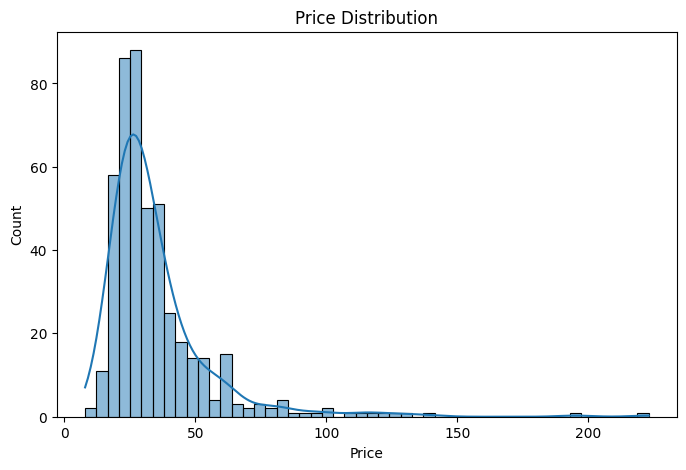

In [74]:
plt.figure(figsize=(8,5))
sns.histplot(data['price(tr)'], bins=50, kde=True)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

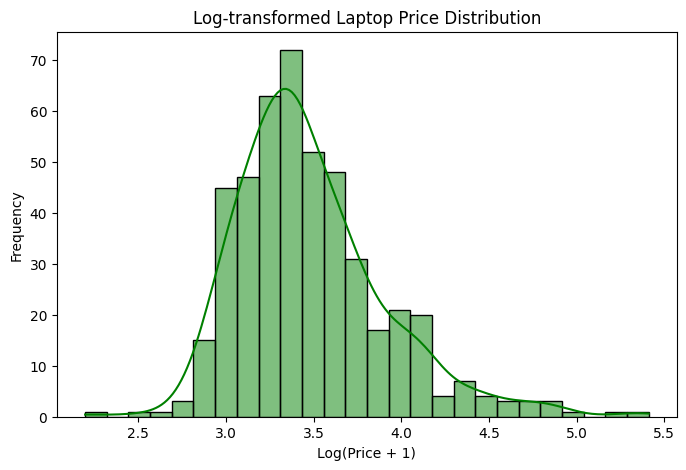

In [75]:

plt.figure(figsize=(8,5))
sns.histplot(np.log1p(data['price(tr)']), kde=True, color='green')
plt.title('Log-transformed Laptop Price Distribution')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Frequency')
plt.show()

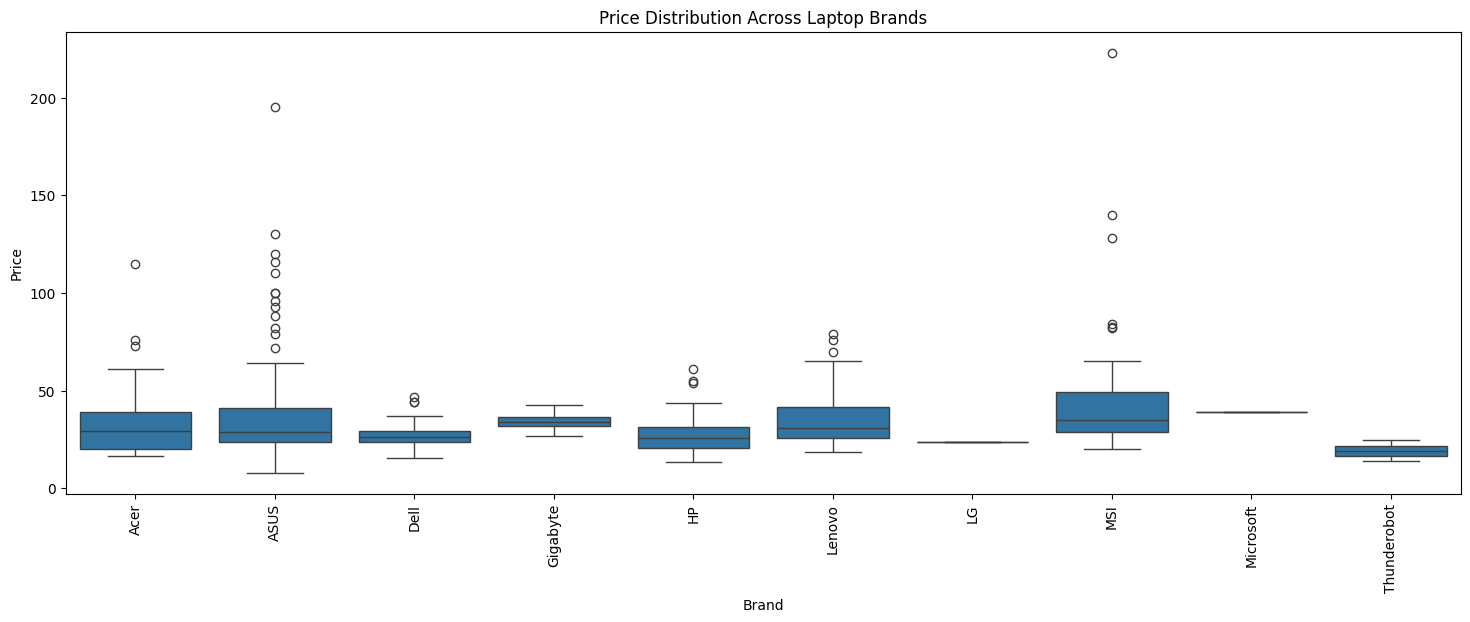

In [76]:
plt.figure(figsize=(18,6))
sns.boxplot(x='brand', y='price(tr)', data=data)
plt.xticks(rotation=90)
plt.title('Price Distribution Across Laptop Brands')
plt.ylabel('Price')
plt.xlabel('Brand')
plt.show()

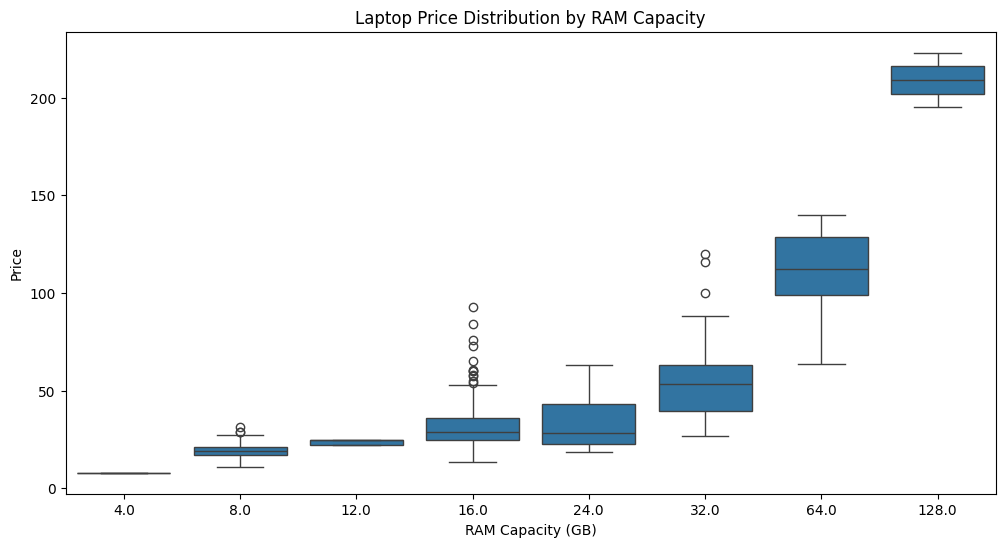

In [77]:
plt.figure(figsize=(12,6))
sns.boxplot(x='RAM', y='price(tr)', data=data)
plt.title('Laptop Price Distribution by RAM Capacity')
plt.xlabel('RAM Capacity (GB)')
plt.ylabel('Price')
plt.show()

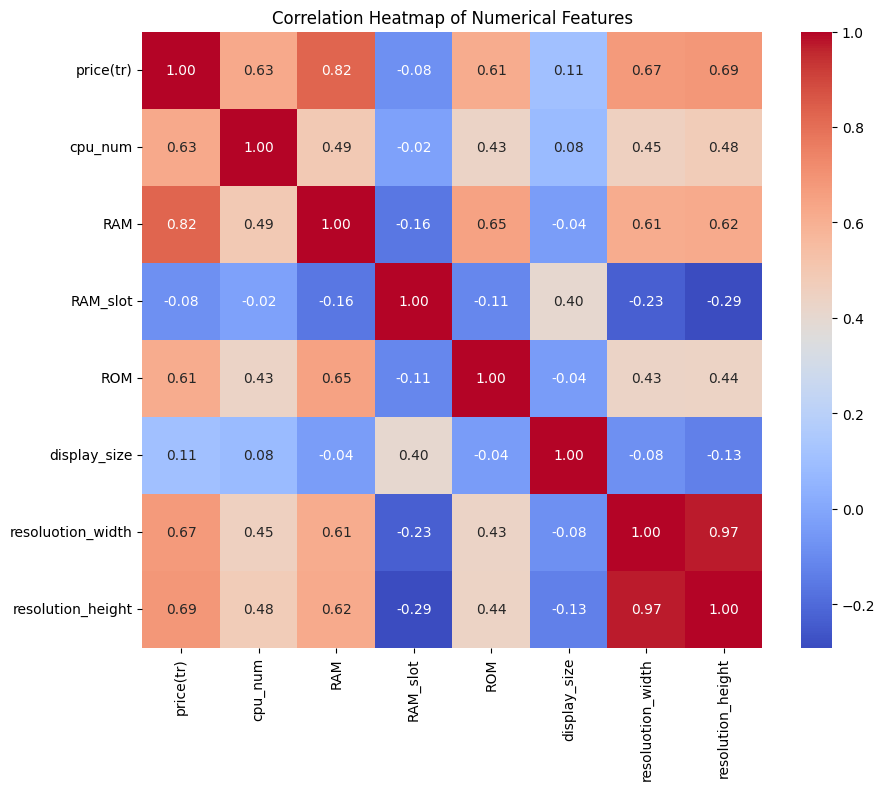

In [78]:
plt.figure(figsize=(10,8))
sns.heatmap(data.select_dtypes(include=['number']).corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

# Apply model

In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [81]:
X = data.drop(columns=['price(tr)', 'name'])
y = np.log(data['price(tr)'])

In [83]:
categorical_cols = ['brand', 'cpu_type', 'cpu_suffix', 'GPU', 'RAM_types']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

In [84]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [85]:
# Mô hình 1: BaggingRegressor
bagging_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=12, min_samples_leaf=2, random_state=42),
        n_estimators=300,
        max_samples=0.85,
        max_features=0.85,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))
])

# Mô hình 2: RandomForestRegressor
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        max_features=0.75,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))
])

for name, pipe in [('BaggingRegressor', bagging_pipeline), ('RandomForestRegressor', rf_pipeline)]:
    pipe.fit(X_train, y_train)

    # Đổi ngược từ np.log() về giá tiền thực bằng np.exp()
    y_test_actual = np.exp(y_test)
    y_pred_actual = np.exp(pipe.predict(X_test))

    print(f"=== {name} ===")
    print(f" - OOB R² Score  : {pipe.named_steps['model'].oob_score_:.4f}")
    print(f" - Test R² Score : {r2_score(y_test_actual, y_pred_actual):.4f}")
    print(f" - Test MAE      : {mean_absolute_error(y_test_actual, y_pred_actual):,.2f}")
    print(f" - Test RMSE     : {np.sqrt(mean_squared_error(y_test_actual, y_pred_actual)):,.2f}\n")

=== BaggingRegressor ===
 - OOB R² Score  : 0.8167
 - Test R² Score : 0.8217
 - Test MAE      : 5.83
 - Test RMSE     : 8.54

=== RandomForestRegressor ===
 - OOB R² Score  : 0.8144
 - Test R² Score : 0.8144
 - Test MAE      : 5.91
 - Test RMSE     : 8.71

